# PrevMaq — Previsão de Falhas em Máquinas Industriais

**Projeto Avaliativo — Módulo 1 · Desenvolvimento de IA para Análise Preditiva [T3] · SENAI/SC**

**Objetivo:** construir um pipeline preditivo que classifique se um equipamento vai **falhar** (`falha_maquina = 1`) ou **operar normalmente** (`falha_maquina = 0`), comparando um **KNN** e uma **Árvore de Decisão** pela acurácia no conjunto de teste.

**Base de dados:** `data/raw/manutencao_preditiva.csv` — dicionário em `docs/dicionario_de_dados.md`.

**Regra da Engenharia:** as colunas `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf` são só para consulta e **não podem** entrar em X.

| Fase | Conteúdo |
|---|---|
| 1 | Análise Exploratória (EDA) |
| 2 | Limpeza e Tratamento de Dados |
| 3 | Feature Engineering |
| 4 | Divisão e Balanceamento |
| 5 | Escalonamento (StandardScaler) |
| 6 | Ajuste de Parâmetros e Combate ao Overfitting |
| 7 | Avaliação da Acurácia e Veredito Final |

## 0. Configuração inicial

Importe as bibliotecas usadas no projeto e carregue a base com **caminho relativo** (o notebook está em `notebooks/`, então o CSV fica em `../data/raw/`).

In [1]:
# 0.1 Importação das bibliotecas (pandas, numpy, matplotlib, seaborn e os módulos do scikit-learn)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

In [2]:
# 0.2 Leitura do CSV com caminho relativo e visualização das primeiras linhas
df = pd.read_csv("../data/raw/manutencao_preditiva.csv")
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


---
## Fase 1 — Análise Exploratória (EDA)

**O que esta fase pede:**
- Dimensões do dataset (linhas e colunas)
- Tipos de dados de cada variável
- Resumo estatístico das colunas numéricas com `.describe()`
- **No mínimo 3 gráficos** (Matplotlib/Seaborn), por exemplo:
  1. Histograma das variáveis preditoras
  2. Gráfico de barras com o desbalanceamento da variável alvo
  3. Mapa de calor com a correlação de Pearson
- Célula de texto analisando os números e os gráficos

In [3]:
# 1.1 Dimensões do dataset (linhas, colunas)
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")

Linhas: 10000 | Colunas: 14


In [4]:
# 1.2 Tipos de dados das variáveis
# info() mostra o tipo de cada coluna e quantos valores não nulos ela tem
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  str    
 2   tipo                     10000 non-null  str    
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 13  falha_rnf                10000 non-null  int64  
dtypes: float64(4), int64(8), str(2)
me

In [5]:
# 1.3 Resumo estatístico descritivo das colunas numéricas (.describe())
df.describe().round(2)

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00,9500.0,9500.00,9500.00,9500.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.00,1539.25,39.97,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.49,180.27,10.00,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.10,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1504.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1613.00,46.70,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


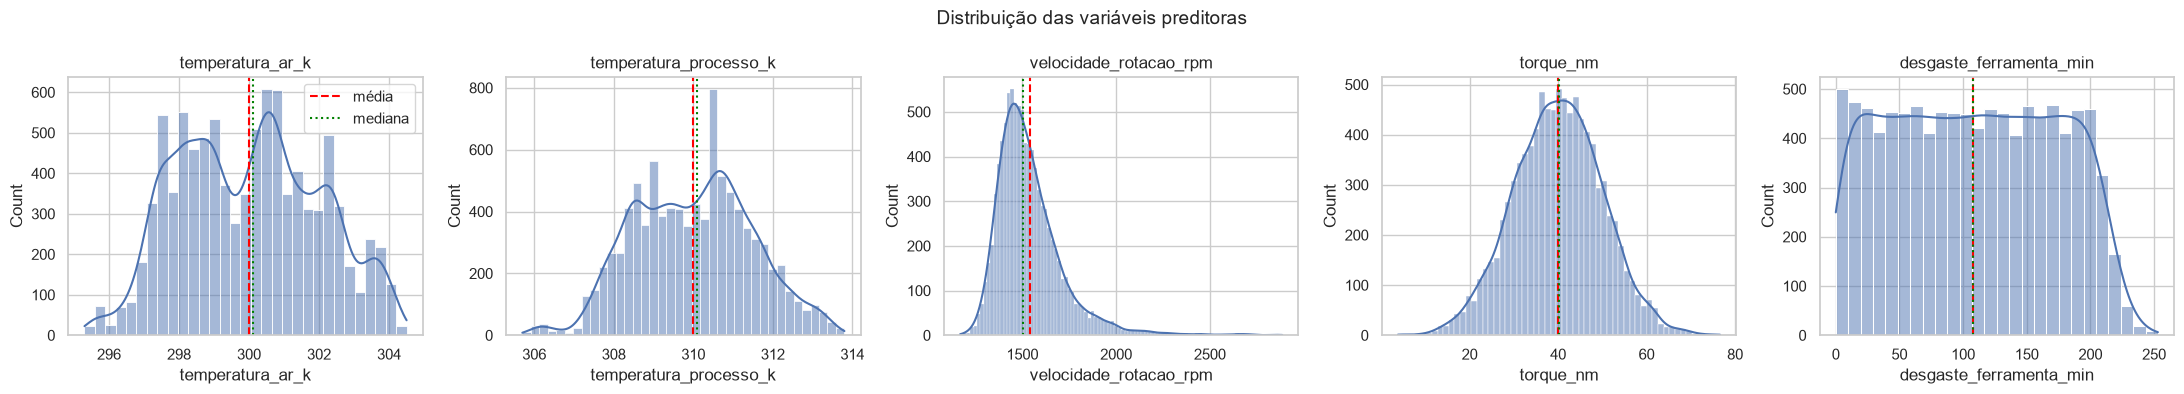

In [6]:
# 1.4 Gráfico 1 — Histogramas das variáveis preditoras numéricas
colunas_sensores = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
]

fig, axes = plt.subplots(1, len(colunas_sensores), figsize=(22, 4))
for ax, col in zip(axes, colunas_sensores):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="média")
    ax.axvline(df[col].median(), color="green", linestyle=":", label="mediana")
    ax.set_title(col)
axes[0].legend()
plt.suptitle("Distribuição das variáveis preditoras", fontsize=14)
plt.tight_layout()
plt.show()

falha_maquina
0    9661
1     339
Name: count, dtype: int64

falha_maquina
0    96.61
1     3.39
Name: proportion, dtype: float64


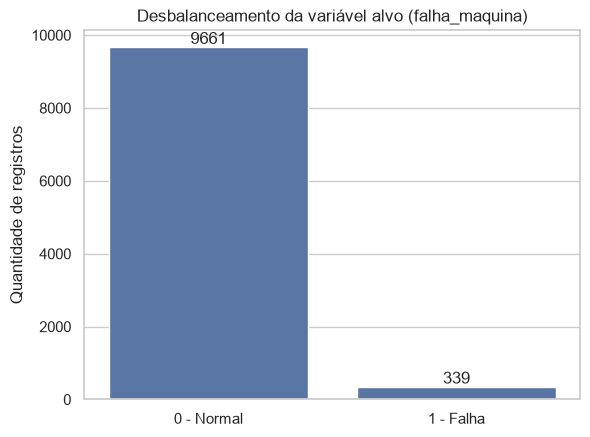

In [7]:
# 1.5 Gráfico 2 — Barras com a contagem/proporção de cada classe de falha_maquina
print(df["falha_maquina"].value_counts())
print()
print((df["falha_maquina"].value_counts(normalize=True) * 100).round(2))

ax = sns.countplot(data=df, x="falha_maquina")
ax.bar_label(ax.containers[0])
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 - Normal", "1 - Falha"])
plt.title("Desbalanceamento da variável alvo (falha_maquina)")
plt.xlabel("")
plt.ylabel("Quantidade de registros")
plt.show()

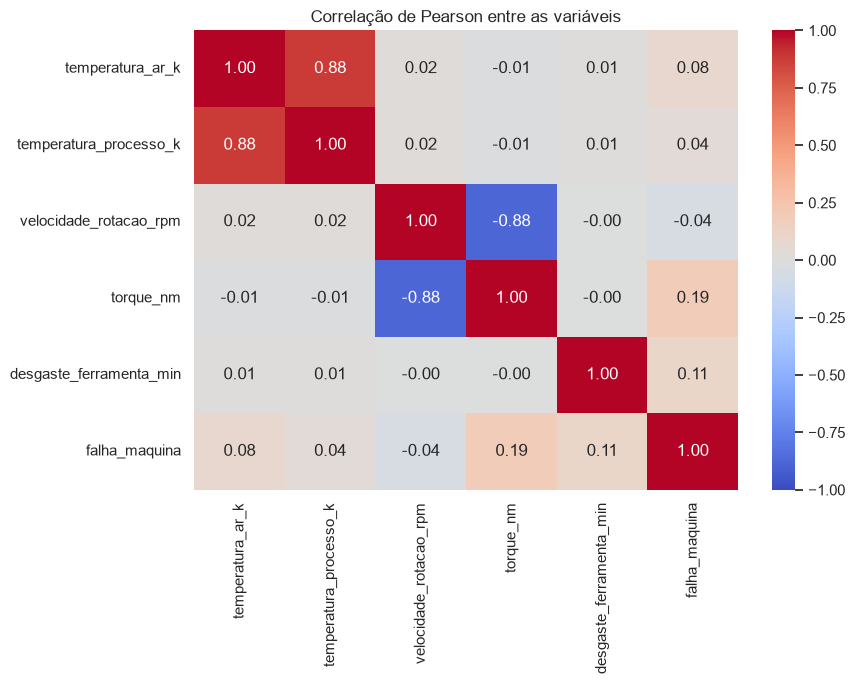

In [8]:
# 1.6 Gráfico 3 — Mapa de calor da correlação de Pearson entre as variáveis numéricas
correlacao = df[colunas_sensores + ["falha_maquina"]].corr(method="pearson")

plt.figure(figsize=(9, 7))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação de Pearson entre as variáveis")
plt.tight_layout()
plt.show()

### ✍️ Análise

> _Escreva aqui a sua análise. Perguntas para guiar o texto (apague-as depois):_
> - Quantas linhas e colunas a base tem? Algum tipo de dado está errado?
> - Em quais variáveis a média e a mediana (50%) estão distantes? O que isso indica sobre a distribuição?
> - Qual a proporção de falhas (classe 1) e de operação normal (classe 0)? Por que isso exige balanceamento?
> - Quais pares de variáveis têm correlação forte no mapa de calor? Isso afeta a escolha das preditoras?
> - Como essas observações direcionam a estratégia de modelagem (limpeza, balanceamento, escalonamento)?

---
## Fase 2 — Limpeza e Tratamento de Dados (Data Prep)

**O que esta fase pede:**
- Identificar e remover linhas duplicadas
- Identificar dados ausentes e imputar com **média ou mediana**, justificando a escolha pela distribuição
- Boxplots para identificar outliers nas variáveis explicativas

In [9]:
# 2.1 Quantidade de linhas duplicadas

In [10]:
# 2.2 Remoção das duplicadas e conferência do novo tamanho da base

#### Justificativa — duplicados

> _Explique o que encontrou e por que a remoção (ou a ausência de duplicados) é importante para o modelo._

In [11]:
# 2.3 Quantidade de valores ausentes por coluna

In [12]:
# 2.4 Comparação de média, mediana (e assimetria) das colunas com valores ausentes

#### Justificativa — média ou mediana?

> _Para cada coluna com valores ausentes, diga se usou média ou mediana e por quê, com base no histograma da Fase 1 e na comparação acima. Lembre a regra vista em aula: quando média e mediana ficam muito distantes, a distribuição é assimétrica e a mediana representa melhor o valor típico._

In [13]:
# 2.5 Imputação dos valores ausentes

In [14]:
# 2.6 Conferência: não deve restar nenhum valor ausente

In [15]:
# 2.7 Boxplots das variáveis explicativas para identificar outliers

### ✍️ Análise

> _Escreva aqui a sua análise. Perguntas para guiar o texto (apague-as depois):_
> - Em quais variáveis aparecem pontos fora dos limites do boxplot (1,5 × IQR)?
> - Esses outliers parecem erro de medição ou situações reais de operação, que podem ser justamente as falhas?
> - Você decidiu manter ou tratar os outliers? Justifique.

---
## Fase 3 — Feature Engineering

**O que esta fase pede:**
- Criar uma **nova coluna numérica** por operação matemática entre colunas existentes, depois do tratamento dos nulos
- Sugestão do enunciado: `potencia = velocidade_rotacao_rpm * torque_nm`
- Se escolher outra combinação, explique aqui e no vídeo

In [16]:
# 3.1 Criação da nova coluna

In [17]:
# 3.2 Validação: conferir que a nova coluna não tem valores ausentes (NaN) e ver o resumo estatístico

#### Justificativa — nova variável

> _Explique o significado físico da nova coluna e por que ela pode ajudar a prever falhas._

---
## Fase 4 — Divisão e Balanceamento dos Dados

**O que esta fase pede:**
- Separar as preditoras (**X**) da variável alvo (**y**)
- Dividir em **treino (80%)** e **teste (20%)** com `stratify=y`
- Aplicar **Random Under Sampling** **somente no treino**, para evitar vazamento de dados

**Antes de montar o X, decida e justifique:**
- Quais colunas saem: identificadores (`udi`, `id_produto`), a variável alvo e as 5 colunas de motivo da falha (regra da Engenharia)
- O que fazer com a coluna categórica `tipo` (L/M/H), já que os modelos só aceitam números

#### Justificativa — escolha das preditoras

> _Liste as colunas que entraram em X e explique por que cada coluna removida ficou de fora._

In [18]:
# 4.1 Separação entre X (preditoras) e y (alvo)

In [19]:
# 4.2 Divisão treino/teste 80/20 com stratify=y (fixe random_state para reprodutibilidade)

In [20]:
# 4.3 Conferência da proporção das classes no treino e no teste

In [21]:
# 4.4 Random Under Sampling SOMENTE no treino (classe majoritária reduzida ao tamanho da minoritária)

In [22]:
# 4.5 Conferência da proporção das classes no treino balanceado

#### Justificativa — divisão e balanceamento

> _Explique: (1) por que usar `stratify=y`; (2) por que balancear só o treino e nunca o teste (data leakage); (3) por que escolheu o Random Under Sampling e qual a desvantagem dele (descartar dados da classe majoritária)._

---
## Fase 5 — Escalonamento de Variáveis (StandardScaler)

**O que esta fase pede:**
- Aplicar o `StandardScaler` **apenas** nas variáveis contínuas usadas pelo **KNN**
- `fit_transform` no **treino** e `transform` no **teste**
- Deixar os dados da **Árvore de Decisão sem escalonamento**, justificando

In [23]:
# 5.1 StandardScaler: fit_transform no treino balanceado e transform no teste (dados do KNN)

In [24]:
# 5.2 Conferência: no treino escalonado, as colunas devem ter média ≈ 0 e desvio padrão ≈ 1

#### Justificativa — por que escalonar só para o KNN?

> _Explique: (1) por que o KNN depende da escala (distância entre pontos; compare a ordem de grandeza da rotação em RPM com a do torque em N·m); (2) por que o `fit` é feito só no treino; (3) por que a Árvore de Decisão não é afetada pela escala (ela divide por limiares em uma variável de cada vez)._

---
## Fase 6 — Ajuste de Parâmetros e Combate ao Overfitting

**O que esta fase pede:**
- **KNN:** variar `n_neighbors` (K) em pelo menos **3 valores ímpares** (ex.: 3, 5, 7) e registrar acurácia de **treino** e **teste**
- **Árvore:** variar `max_depth` em pelo menos **3 limites** (ex.: 3, 5, None) e registrar acurácia de **treino** e **teste**
- Texto apontando onde houve overfitting e qual configuração ficou estável no teste

In [25]:
# 6.1 KNN — treinar com cada valor de K e registrar acurácia de treino e teste

In [26]:
# 6.2 KNN — tabela (DataFrame) com os resultados

In [27]:
# 6.3 Árvore de Decisão — treinar com cada max_depth e registrar acurácia de treino e teste

In [28]:
# 6.4 Árvore de Decisão — tabela (DataFrame) com os resultados

In [29]:
# 6.5 (Opcional) Gráfico comparando acurácia de treino x teste para cada configuração

### ✍️ Análise

> _Escreva aqui a sua análise. Perguntas para guiar o texto (apague-as depois):_
> - Em quais configurações a acurácia de treino ficou muito acima da de teste (sinal de overfitting)?
> - Como o K pequeno no KNN e o max_depth=None na Árvore se comportaram? Por quê?
> - Qual configuração de cada modelo teve o melhor equilíbrio entre treino e teste?

---
## Fase 7 — Avaliação da Acurácia e Veredito Final

**O que esta fase pede:**
- Calcular e exibir a **acurácia final no teste** do **melhor KNN** e da **melhor Árvore de Decisão**
- Comparar as taxas de acerto e concluir qual modelo a empresa deve adotar

In [30]:
# 7.1 Treinar o melhor KNN e calcular a acurácia no teste

In [31]:
# 7.2 Treinar a melhor Árvore de Decisão e calcular a acurácia no teste

In [32]:
# 7.3 Comparação lado a lado das acurácias

### ✍️ Veredito final

> _Compare os valores numéricos de acurácia no teste, indique o modelo de maior desempenho e justifique por que ele deve ser adotado pela empresa. Se quiser, comente as limitações (por exemplo, a acurácia sozinha em um problema de falhas raras)._